In [89]:
import warnings
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "models" / "src" ))

from common import contract, data, paths, plots
from common.data import read_csv, show_dataset

SEED = contract.SEED
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios

DATA_DIR = paths.RAW
OUT_DIR = paths.SPLITS

plots.aplicar_estilo()

print(f"dados em {DATA_DIR}")
print(f"saida em {OUT_DIR}")
print(f"semente: {SEED}")

ARQUIVOS = (
    sorted(DATA_DIR.rglob("ifpee*.csv")) # utilizar apena dados dos inversores e.x
)
print(f"{len(ARQUIVOS)} arquivos" + NL)



# Downsample dataset 
def downsample(df: pd.DataFrame, rules, freq='1D', limiar_zero=0.05):

    d = df.copy().reset_index(drop=True)
    dia = d["datetime"].dt.normalize()
    chave = [d["inversor"], dia]

    # Ainda há mais de uma leitura por estação/dia?
    if d.groupby(chave).size().gt(1).any():
        diurno = d["datetime"].dt.hour.between(6, 17)

        # Condição de leitura inválida. Ajuste aqui se necessário.
        invalido = d["PCA"].isna() | d["PCA"].eq(0)

        # Fração de leituras inválidas restritas ao período diurno de cada
        # estação/dia. Com amostragem regular, a fração de leituras equivale
        # à fração de tempo dentro da janela.
        zeros_diurno = (invalido & diurno).groupby(chave).transform("sum")
        total_diurno = diurno.groupby(chave).transform("sum")

        frac_zero = zeros_diurno / total_diurno.where(total_diurno > 0)

        # Descarta somente quando MAIS de x% das leituras diurnas estão zeradas.
        descartar = frac_zero > limiar_zero
        tem_diurno = total_diurno > 0

        d = d.loc[tem_diurno & ~descartar]
    else:
        # Fallback para quando a célula é reexecutada com df já diário.
        d = d.loc[d["PCA"].notna() & d["PCA"].ne(0)]

    return show_dataset(
        d.groupby(['inversor', pd.Grouper(key='datetime', freq=freq)]) \
        .agg(rules)                                                    \
        .reset_index(),
        colunas=True,
    )


dados em C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\raw
saida em C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\splited
semente: 42
9 arquivos



In [90]:
partes: list[pd.DataFrame] = []

for p in ARQUIVOS:
    df = read_csv(p, parse=("datetime", "timestamp"))
    df["inversor"] = p.stem.split("_")[0]
    partes.append(df)

    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

raw: pd.DataFrame = pd.concat(partes, ignore_index=True)
del partes

  raw        ifpee1_2021        45872 linhas  18 colunas
  raw        ifpee1_2022        43750 linhas  18 colunas
  raw        ifpee1_2023        46380 linhas  18 colunas
  raw        ifpee1_2024        46514 linhas  19 colunas
  raw        ifpee1_2025        44969 linhas  19 colunas
  raw        ifpee2_2024        46514 linhas  19 colunas
  raw        ifpee2_2025        44969 linhas  19 colunas
  raw        ifpee3_2024        46514 linhas  19 colunas
  raw        ifpee3_2025        44969 linhas  19 colunas


In [91]:
raw = raw.drop(columns=[c for c in raw.columns if c in {"condicao", "velocidade_vento", "timestamp"}])

df = raw.copy()

df.PCA = df.PCA.fillna(0)

show_dataset(df, colunas=True).head()


pool: 410451 linhas, 16 colunas
colunas: ['PCA', 'angzen', 'datetime', 'doy', 'ghi_cs', 'ghit', 'hora_dec', 'inversor', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'temperatura_ambiente']

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    9683


,temperatura_ambiente,doy,ghi_cs,hora_dec,kc,angzen,ghit,PCA,jacques,sandia,sandia_cell,pvsyst_cell,datetime,ioeff,kt,inversor
0,29.740,4,971.194471,10.150000,1.058490,25.263877,924.576334,1.28,53.714096,53.072812,60.619963,55.564373,2021-01-04 10:05:00,1411.074617,0.805575,ifpee1
1,30.222,4,976.384198,10.200000,1.059624,24.284699,935.169209,1.70,55.256880,54.528103,62.127197,56.342243,2021-01-04 10:10:00,1411.074617,0.804377,ifpee1
2,30.548,4,984.658595,10.283333,1.080374,23.325885,966.293219,1.72,56.416083,55.663052,63.515055,57.537569,2021-01-04 10:15:00,1411.074617,0.820995,ifpee1
3,30.900,4,992.418037,10.366667,0.846297,22.390090,786.259644,1.70,51.416415,50.859537,57.272172,52.861045,2021-01-04 10:20:00,1411.074617,0.643736,ifpee1
4,29.426,4,999.658520,10.450000,0.742374,21.480359,710.256671,1.00,48.439875,47.886373,53.657849,49.264204,2021-01-04 10:25:00,1411.074617,0.565181,ifpee1


In [92]:
outages = (df.PCA == 0) & (df.ghit > 50)
clipping = (df.PCA >= 1.95)
low_irradiance = (df.ghit < 5)
high_temperature = (df.temperatura_ambiente >= 50)

# filter out outages, clipping, low irradiance, and high temperature
df = df[~outages & ~clipping & ~low_irradiance & ~high_temperature]

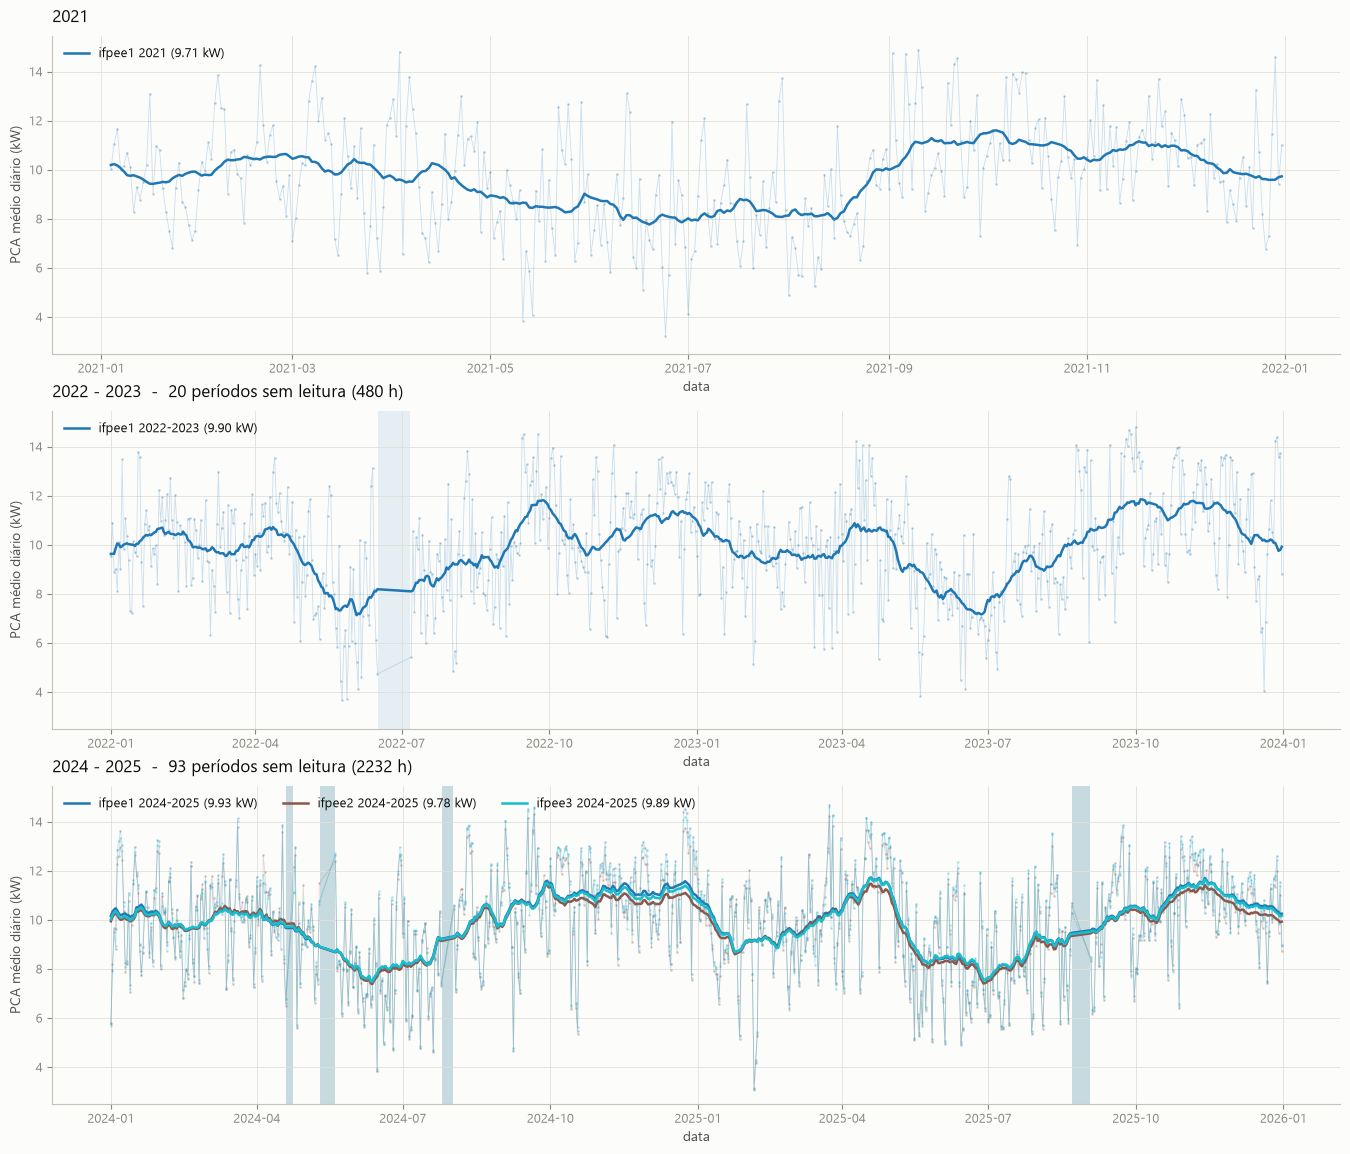

In [99]:
plots.plot_time_series(df.reset_index(), janela=30)

## Downsampling dataset

In [94]:
regras = {
    'PCA': 'sum',
    'ghit': 'sum',
    'ioeff': 'mean',
    'jacques': 'mean',
    'kc': 'mean',
    'kt': 'mean',
    'pvsyst_cell': 'mean',
    'sandia': 'mean',
    'sandia_cell': 'mean',
    'temperatura_ambiente': 'mean',
}

df = downsample(df, regras, freq='1h', limiar_zero=1.0)



pool: 36211 linhas, 12 colunas
colunas: ['PCA', 'datetime', 'ghit', 'inversor', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'temperatura_ambiente']

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    150


## Split

In [95]:
def get_split(dataset: pd.DataFrame, rate=0.8):
    train = dataset.sample(frac=rate, random_state=SEED)
    validation = dataset.drop(train.index)
    return train.index, validation.index

def year_seasons(md):
    if 320 <= md < 621:
        return 'outono'
    elif 621 <= md < 922:
        return 'inverno'
    elif 922 <= md < 1221:
        return 'primavera'
    else:
        return 'verão'


In [96]:

df['season'] = (
    df['datetime'].dt.month * 100
    + df['datetime'].dt.day
).apply(year_seasons)

df.head()


,inversor,datetime,PCA,ghit,ioeff,jacques,kc,kt,pvsyst_cell,sandia,sandia_cell,temperatura_ambiente,season
0,ifpee1,2021-01-04 10:00:00,17.21,9562.653874,1411.074617,54.099125,0.932397,0.710216,55.258620,53.437436,60.508208,30.977273,verão
1,ifpee1,2021-01-04 11:00:00,14.39,7829.820438,1411.074617,50.644784,0.639949,0.489073,51.419582,50.138249,55.441067,33.195000,verão
2,ifpee1,2021-01-04 12:00:00,9.01,4385.019199,1411.074617,36.106660,0.364946,0.276865,38.085010,35.825403,38.834023,27.878500,verão
3,ifpee1,2021-01-04 13:00:00,9.36,4365.115143,1411.074617,37.121381,0.395879,0.294856,38.390182,36.898864,39.888464,28.230000,verão
4,ifpee1,2021-01-04 14:00:00,10.81,5847.939861,1411.074617,42.691695,0.616089,0.437919,43.661917,42.349686,46.326991,30.050333,verão


In [97]:
# pegar somente o ultimo ano para teste
test_split = (
  (df.datetime.dt.year == df.datetime.dt.year.max()))

splits: dict[str, pd.DataFrame] = {
  'test': df[test_split],
  'train': df[~test_split],
  'validation': df[~test_split],
}

# garantir pelo menos uma estação do ano no split
primavera = (df['season'] == 'primavera')
inverno = (df['season'] == 'inverno')
outono = (df['season'] == 'outono')
verão = (df['season'] == 'verão')

for season in (primavera, inverno, outono, verão):
  train_index, validation_index = get_split(df[season & ~test_split], rate=.65)
  splits['train'] = splits['train'].drop(validation_index)
  splits['validation'] = splits['validation'].drop(train_index)


In [98]:
escritos = data.save_splits(splits, df)
for caminho, n in escritos.items():
    print(f"  {caminho.relative_to(paths.ROOT)!s:34} {n:6} linhas")


  data\splited\test.csv               12126 linhas
  data\splited\train.csv              15656 linhas
  data\splited\validation.csv          8429 linhas
  data\splited\test\ifpee1.csv         4042 linhas
  data\splited\test\ifpee2.csv         4042 linhas
  data\splited\test\ifpee3.csv         4042 linhas
